In [1]:
import pandas as pd 
import matplotlib 
import matplotlib.pyplot as plt

In [2]:

# Uploading the vibriobaseline CSV 
vibriobaseline_path = r"C:\Users\marin\Documents\Bioluminescence\bacteria data\vibriobaseline.tsv"

vibriobaseline_df = pd.read_csv(vibriobaseline_path, sep=r'\s+', header = 0)

vibriobaseline_df.head(5)

,wavelength_nm,intensity_raw_shifted,intensity_smoothed_shifted
0,418.874,-18.28,-12.93
1,419.133,6.72,-12.82
2,419.392,-45.28,-12.68
3,419.651,12.72,-12.53
4,419.910,-22.28,-12.36


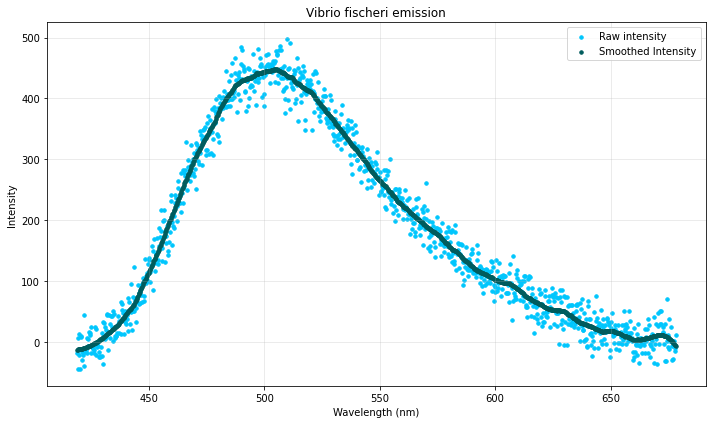

In [3]:
# ploting the vibriobaseline file 

plt.figure(figsize=(10, 6))

plt.scatter(
    vibriobaseline_df['wavelength_nm'],
    vibriobaseline_df['intensity_raw_shifted'],
    s=12,
    color="#00C6FD",  # Baby blue
    label='Raw intensity'
)

plt.scatter(
    vibriobaseline_df['wavelength_nm'],
    vibriobaseline_df['intensity_smoothed_shifted'],
    s=12,
    color="#005C5D",  # Green-blue / teal
    label='Smoothed Intensity'
)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Intensity')
plt.title('Vibrio fischeri emission')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Import the bacteriahaddock file 

bacteriahaddock_path = r"C:\Users\marin\Documents\Bioluminescence\bacteria data\bacteriahaddock.csv"

bacteriahaddock_df = pd.read_csv(bacteriahaddock_path, sep=r'\s+', header = 0)
bh_headers = ["wavelength_nm", "irradiance", "uncertainty"] 
bacteriahaddock_df.columns = bh_headers
bacteriahaddock_df.head(5)

,wavelength_nm,irradiance,uncertainty
0,394.630,369,10.444444
1,394.890,258,12.444444
2,395.150,336,31.000000
3,395.409,163,13.111111
4,395.669,352,-4.444444


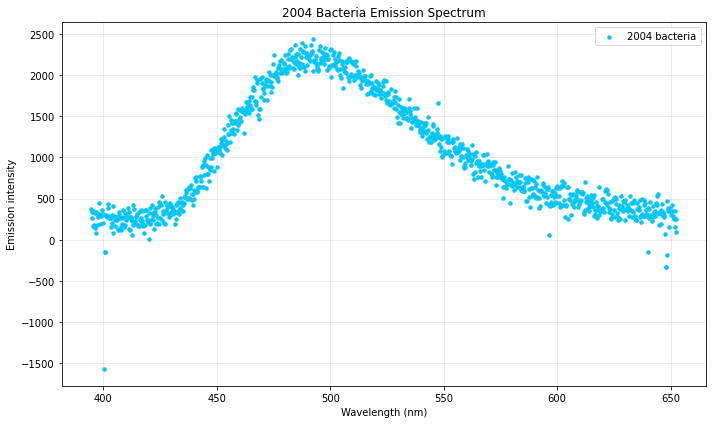

In [5]:
# plot the bacteriahaddock file
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    bacteriahaddock_df["wavelength_nm"],
    bacteriahaddock_df["irradiance"],
    s=12,
    color="#00C6FD",
    label='2004 bacteria'
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Emission intensity")
plt.title("2004 Bacteria Emission Spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Import the vibriohaddock file 

vibriohaddock_path = r"C:\Users\marin\Documents\Bioluminescence\bacteria data\vibriohaddock.csv"

vibriohaddock_df = pd.read_csv(vibriohaddock_path, sep=r'\s+', skiprows=1, header =None)
vh_headers = ["wavelength_nm", "substracted irradiance"] 
vibriohaddock_df.columns = vh_headers
vibriohaddock_df.head(5)


,wavelength_nm,substracted irradiance
0,418.874,-51
1,419.133,-26
2,419.392,-78
3,419.651,-20
4,419.910,-55


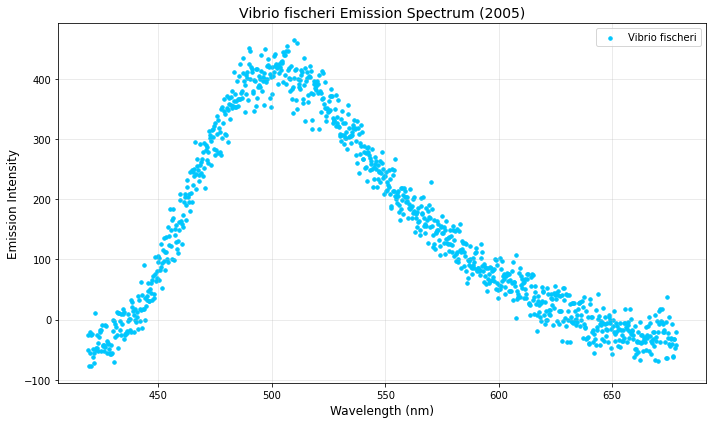

In [7]:
# Ploting the vibriohaddock file 
plt.figure(figsize=(10, 6))

plt.scatter(
    vibriohaddock_df["wavelength_nm"],
    vibriohaddock_df["substracted irradiance"],
    s=12,
    color="#00C6FD",
    label='Vibrio fischeri'
)

plt.xlabel("Wavelength (nm)", fontsize=12)
plt.ylabel("Emission Intensity", fontsize=12)
plt.title("Vibrio fischeri Emission Spectrum (2005)", fontsize=14)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Import the bacteriacurve file 

bacteriacurve_path = r"C:\Users\marin\Documents\Bioluminescence\bacteria data\bacteriacurve.csv"

bacteriacurve_df = pd.read_csv(bacteriacurve_path, sep=r'\s+',skiprows=1, header =None)
bacteriacurve_df.head()


,0,1
0,418.874,-0.023746
1,419.133,0.030222
2,419.392,-0.082031
3,419.651,0.043174
4,419.910,-0.032381


In [9]:
# In order to check if this column is really the normalized data 
bacteriacurve_df[1].max()

1.0

In [10]:
# Adding the header 
bc_headers = ['wavelength', 'normalized emission']
bacteriacurve_df.columns = bc_headers
bacteriacurve_df.head()

,wavelength,normalized emission
0,418.874,-0.023746
1,419.133,0.030222
2,419.392,-0.082031
3,419.651,0.043174
4,419.910,-0.032381


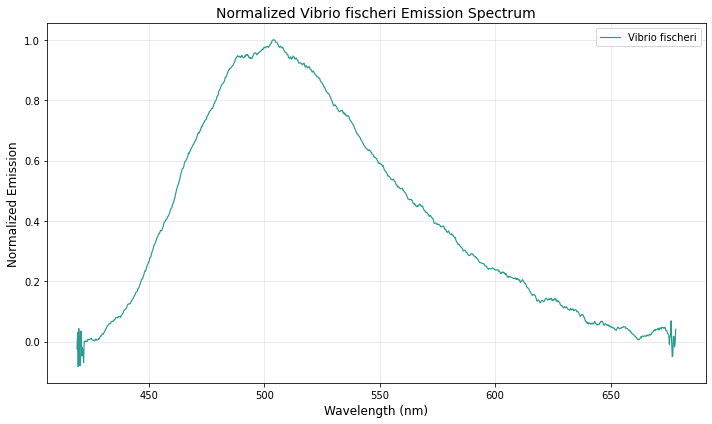

In [11]:
# Plot the bacteriacurve file 

plt.figure(figsize=(10, 6))

plt.plot(
    bacteriacurve_df["wavelength"],
    bacteriacurve_df["normalized emission"],
    color="#2A9D8F",
    linewidth=1.2,
    label='Vibrio fischeri'
)

plt.xlabel("Wavelength (nm)", fontsize=12)
plt.ylabel("Normalized Emission", fontsize=12)
plt.title("Normalized Vibrio fischeri Emission Spectrum", fontsize=14)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

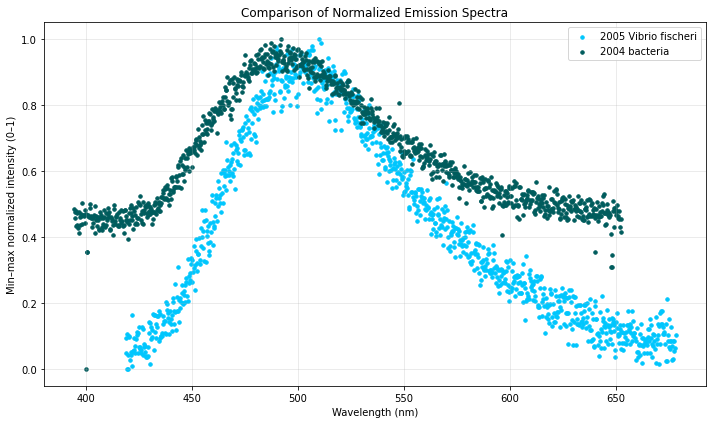

In [12]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Normalize each intensity dataset independently
normalized_df = {}
normalized_df["intensity_normalized"] = MinMaxScaler().fit_transform(
    vibriobaseline_df[["intensity_raw_shifted"]]
)

normalized_df["irradiance_normalized"] = MinMaxScaler().fit_transform(
    bacteriahaddock_df[["irradiance"]]
)

# Plot
plt.figure(figsize=(10, 6))

plt.scatter(
    vibriobaseline_df["wavelength_nm"],
    normalized_df["intensity_normalized"],
    s=12,
    color="#00C6FD",
    label="2005 Vibrio fischeri"
)

plt.scatter(
    bacteriahaddock_df["wavelength_nm"],
    normalized_df["irradiance_normalized"],
    s=12,
    color="#005C5D",
    label="2004 bacteria"
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Min–max normalized intensity (0–1)")
plt.title("Comparison of Normalized Emission Spectra")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()